# Olist Brazilian E-Commerce: Exploratory Analysis

This notebook uses Python and Pandas to validate the Olist data and create visual evidence for the SQL findings. The analysis focuses on delivered-order trends, product categories, delivery performance, and review scores.

The first section prepares the Colab environment and confirms that the source files were loaded correctly.

## 1. Import libraries

- `pandas` reads and analyzes tabular data.
- `matplotlib` displays the charts.
- `seaborn` applies a consistent visual theme.
- `Path` helps locate the uploaded CSV files.

In [1]:
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

print("Python environment is ready.")

Python environment is ready.


## 2. Upload the dataset

Upload the extracted Olist CSV files using the Files panel on the left side of Google Colab. The uploaded files are stored temporarily and must be uploaded again if the runtime is reset.

In [2]:
from pathlib import Path

data_dir = Path("/")
csv_files = sorted(data_dir.glob("*.csv"))

print(f"Found {len(csv_files)} CSV files:")

for path in csv_files:
    print("-", path.name)

Found 9 CSV files:
- olist_customers_dataset.csv
- olist_geolocation_dataset.csv
- olist_order_items_dataset.csv
- olist_order_payments_dataset.csv
- olist_order_reviews_dataset.csv
- olist_orders_dataset.csv
- olist_products_dataset.csv
- olist_sellers_dataset.csv
- product_category_name_translation.csv


The source dataset contains nine CSV files. This notebook initially loads the seven tables required for the main analysis. The geolocation and seller tables are not loaded yet because they are not needed for the first set of charts.

## 3. Load the analysis tables

In [3]:
def find_csv(filename):
    file_path = data_dir / filename

    if not file_path.exists():
        raise FileNotFoundError(
            f"Could not find {filename} in {data_dir}."
        )

    return file_path


orders = pd.read_csv(
    find_csv("olist_orders_dataset.csv")
)

order_items = pd.read_csv(
    find_csv("olist_order_items_dataset.csv")
)

payments = pd.read_csv(
    find_csv("olist_order_payments_dataset.csv")
)

reviews = pd.read_csv(
    find_csv("olist_order_reviews_dataset.csv")
)

products = pd.read_csv(
    find_csv("olist_products_dataset.csv")
)

customers = pd.read_csv(
    find_csv("olist_customers_dataset.csv")
)

category_translation = pd.read_csv(
    find_csv("product_category_name_translation.csv")
)

print("Analysis tables loaded successfully.")

Analysis tables loaded successfully.


## 4. Confirm table sizes

`shape[0]` returns the number of rows and `shape[1]` returns the number of columns. These row counts should match the SQL import checks.

In [4]:
tables = {
    "customers": customers,
    "order_items": order_items,
    "payments": payments,
    "reviews": reviews,
    "orders": orders,
    "products": products,
    "category_translation": category_translation,
}

table_summary = pd.DataFrame(
    [
        {"table_name": name, "rows": df.shape[0], "columns": df.shape[1]}
        for name, df in tables.items()
    ]
)

table_summary

,table_name,rows,columns
0,customers,99441,5
1,order_items,112650,7
2,payments,103886,5
3,reviews,99224,7
4,orders,99441,8
5,products,32951,9
6,category_translation,71,2


## 5. Preview the orders table

`head()` displays the first five rows. It is used to understand the columns and confirm that the file was parsed correctly; it is not an analysis result.

In [5]:
orders.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


## 6. Convert order timestamps

CSV files do not permanently store data types. Pandas initially reads the timestamp columns as text, so they are converted to `datetime` before calculating months or delivery durations. `errors="coerce"` converts blank or invalid values to the Pandas missing-date value `NaT` rather than inventing a date.

In [6]:
order_date_columns = [
    "order_purchase_timestamp",
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "order_estimated_delivery_date",
]

for column in order_date_columns:
    orders[column] = pd.to_datetime(orders[column], errors="coerce")

orders[order_date_columns].dtypes

,0
order_purchase_timestamp,datetime64[ns]
order_approved_at,datetime64[ns]
order_delivered_carrier_date,datetime64[ns]
order_delivered_customer_date,datetime64[ns]
order_estimated_delivery_date,datetime64[ns]


## 7. Validate the main order counts

This check confirms that Python is using the same source data and definitions as the SQL analysis.

In [7]:
delivered_orders = orders[orders["order_status"] == "delivered"].copy()

validation_summary = pd.Series(
    {
        "total_order_rows": len(orders),
        "unique_order_ids": orders["order_id"].nunique(),
        "delivered_orders": len(delivered_orders),
        "delivered_orders_missing_delivery_date": (
            delivered_orders["order_delivered_customer_date"].isna().sum()
        ),
    },
    name="value",
)

validation_summary

,value
total_order_rows,99441
unique_order_ids,99441
delivered_orders,96478
delivered_orders_missing_delivery_date,8


### Expected validation results

- Total order rows: **99,441**
- Unique order IDs: **99,441**
- Delivered orders: **96,478**
- Delivered orders missing an actual delivery date: **8**

If these values match, the data-loading stage is complete and the next section can begin the visual analysis.

## 8. Monthly Delivered Order Trend

This section analyzes the number of delivered orders by purchase month. Only orders with `order_status = 'delivered'` are included. The monthly order count is calculated using distinct `order_id` values.

In [8]:
# Create a year-month column from the purchase timestamp
delivered_orders["order_month"] = (
    delivered_orders["order_purchase_timestamp"]
    .dt.strftime("%Y-%m")
)

# Count distinct delivered orders by month
monthly_orders = (
    delivered_orders
    .groupby("order_month")["order_id"]
    .nunique()
)

# Convert the result back into a DataFrame
monthly_orders = monthly_orders.reset_index()

# Rename the order-count column
monthly_orders = monthly_orders.rename(
    columns={
        "order_id": "delivered_orders"
    }
)

monthly_orders.head()

,order_month,delivered_orders
0,2016-09,1
1,2016-10,265
2,2016-12,1
3,2017-01,750
4,2017-02,1653


### Monthly Trend Visualization

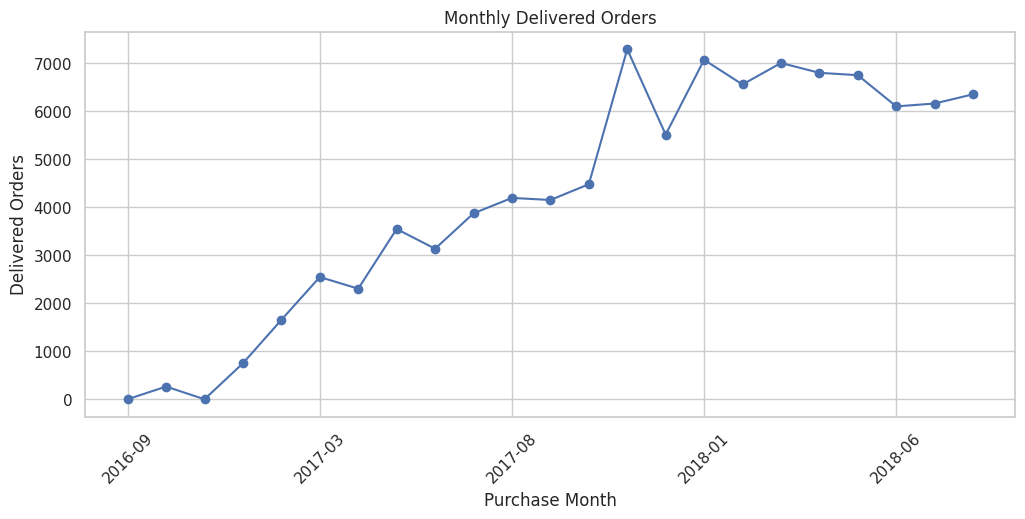

In [9]:
monthly_orders.plot(
    x="order_month",
    y="delivered_orders",
    kind="line",
    marker="o",
    figsize=(12, 5),
    legend=False
)

plt.title("Monthly Delivered Orders")
plt.xlabel("Purchase Month")
plt.ylabel("Delivered Orders")
plt.xticks(rotation=45)
plt.show()

### Finding

Delivered-order volume increased substantially during 2017 and reached its highest level in November 2017. Monthly volume remained relatively stable at a higher level during 2018. The sparse 2016 records are not treated as a complete comparison period.

## 9. Product Category Performance

This section compares delivered product categories using merchandise value. Merchandise value is calculated as the sum of item prices and does not include freight.

In [10]:
delivered_order_ids = delivered_orders[
    ["order_id"]
]

delivered_items = pd.merge(
    order_items,
    delivered_order_ids,
    on="order_id",
    how="inner"
)

delivered_items.shape

(110197, 7)

In [11]:
# Keep only the product ID and category columns
product_categories = products[
    ["product_id", "product_category_name"]
]

# Add the original Portuguese category to each delivered item
delivered_items = pd.merge(
    delivered_items,
    product_categories,
    on="product_id",
    how="left"
)

# Add the English category translation
delivered_items = pd.merge(
    delivered_items,
    category_translation,
    on="product_category_name",
    how="left"
)

delivered_items.shape

(110197, 9)

In [12]:
# Start with the English category name
delivered_items["product_category"] = (
    delivered_items["product_category_name_english"]
)

# If English is missing, use the original Portuguese category
delivered_items["product_category"] = (
    delivered_items["product_category"]
    .fillna(delivered_items["product_category_name"])
)

# If both are missing, label the category as Unknown
delivered_items["product_category"] = (
    delivered_items["product_category"]
    .fillna("Unknown")
)

In [13]:
category_sales = (
    delivered_items
    .groupby("product_category")["price"]
    .sum()
)

category_sales = category_sales.reset_index()

category_sales = category_sales.rename(
    columns={
        "price": "merchandise_value"
    }
)

category_sales = category_sales.sort_values(
    "merchandise_value",
    ascending=False
)

top_categories = category_sales.head(10)

top_categories

,product_category,merchandise_value
44,health_beauty,1233131.72
73,watches_gifts,1166176.98
8,bed_bath_table,1023434.76
68,sports_leisure,954852.55
16,computers_accessories,888724.61
40,furniture_decor,711927.69
50,housewares,615628.69
21,cool_stuff,610204.10
6,auto,578966.65
72,toys,471286.48


### Top Product Categories by Merchandise Value

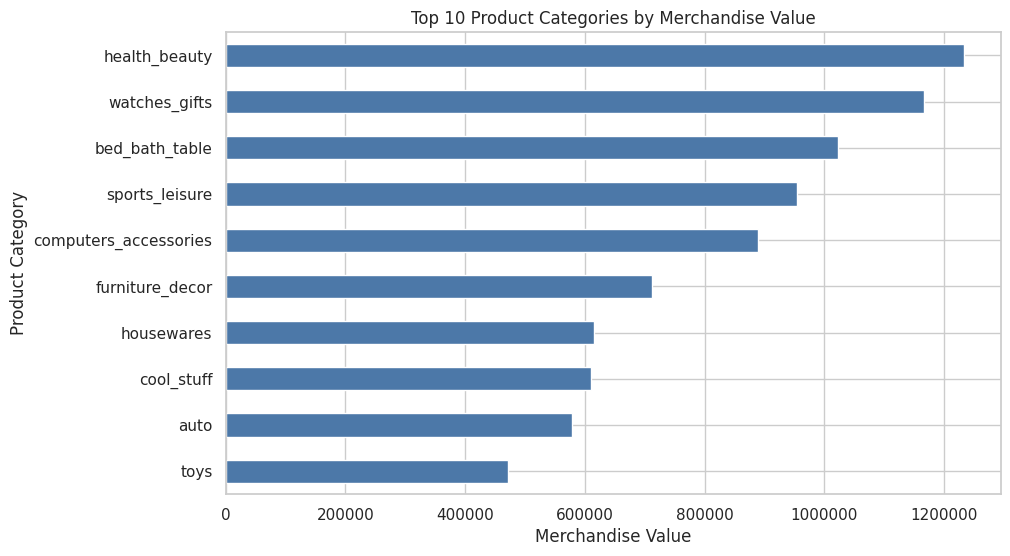

In [14]:
top_categories_plot = top_categories.sort_values(
    "merchandise_value",
    ascending=True
)

top_categories_plot.plot(
    x="product_category",
    y="merchandise_value",
    kind="barh",
    figsize=(10, 6),
    legend=False,
    color="#4C78A8"
)

plt.title("Top 10 Product Categories by Merchandise Value")
plt.xlabel("Merchandise Value")
plt.ylabel("Product Category")
plt.ticklabel_format(style="plain", axis="x")
plt.show()

### Finding

Health and beauty generated the highest delivered merchandise value, followed by watches and gifts and bed, bath, and table products. The ranking is based on item prices and does not include freight or indicate profitability.

## 10. Delivery Performance and Review Scores

This section compares average review scores between on-time and late delivered orders. Orders with multiple review records are first reduced to one average review score per order.

In [15]:
order_review_scores = (
    reviews
    .groupby("order_id")["review_score"]
    .mean()
)

order_review_scores = order_review_scores.reset_index()

order_review_scores = order_review_scores.rename(
    columns={
        "review_score": "order_review_score"
    }
)

order_review_scores.head()

,order_id,order_review_score
0,00010242fe8c5a6d1ba2dd792cb16214,5.0
1,00018f77f2f0320c557190d7a144bdd3,4.0
2,000229ec398224ef6ca0657da4fc703e,5.0
3,00024acbcdf0a6daa1e931b038114c75,4.0
4,00042b26cf59d7ce69dfabb4e55b4fd9,5.0


In [16]:
delivery_reviews = pd.merge(
    delivered_orders,
    order_review_scores,
    on="order_id",
    how="inner"
)

delivery_reviews = delivery_reviews.dropna(
    subset=[
        "order_delivered_customer_date",
        "order_estimated_delivery_date"
    ]
)

delivery_reviews.shape

(95824, 10)

In [17]:
delivery_reviews["delivery_status"] = "Late"

on_time_condition = (
    delivery_reviews["order_delivered_customer_date"].dt.date
    <=
    delivery_reviews["order_estimated_delivery_date"].dt.date
)

delivery_reviews.loc[
    on_time_condition,
    "delivery_status"
] = "On time"

delivery_reviews.shape

(95824, 11)

In [18]:
delivery_reviews[
    "delivery_status"
].value_counts()

,count
delivery_status,
On time,89443
Late,6381


In [19]:
delivery_review_summary = (
    delivery_reviews
    .groupby("delivery_status")[
        "order_review_score"
    ]
    .mean()
)

delivery_review_summary = (
    delivery_review_summary.reset_index()
)

delivery_review_summary = (
    delivery_review_summary.rename(
        columns={
            "order_review_score":
            "average_review_score"
        }
    )
)

delivery_review_summary[
    "average_review_score"
] = delivery_review_summary[
    "average_review_score"
].round(2)

delivery_review_summary

,delivery_status,average_review_score
0,Late,2.27
1,On time,4.29


### Average Review Score by Delivery Status

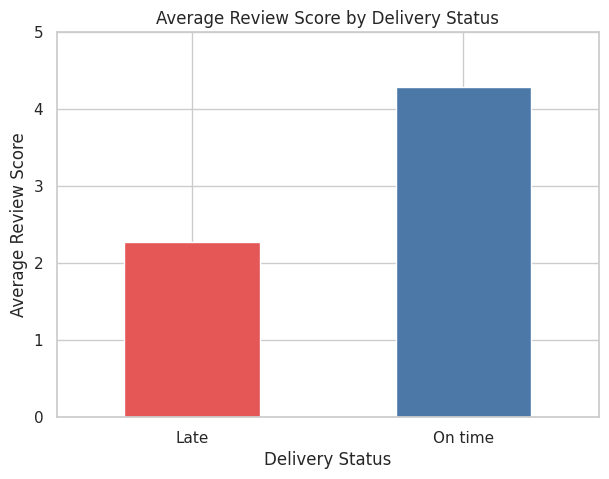

In [20]:
delivery_review_summary.plot(
    x="delivery_status",
    y="average_review_score",
    kind="bar",
    figsize=(7, 5),
    legend=False,
    color=["#E45756", "#4C78A8"]
)

plt.title("Average Review Score by Delivery Status")
plt.xlabel("Delivery Status")
plt.ylabel("Average Review Score")
plt.ylim(0, 5)
plt.xticks(rotation=0)
plt.show()

### Finding

On-time delivered orders received an average review score of 4.29, compared with 2.27 for late orders. This result shows a strong association between delivery performance and customer satisfaction, but it does not prove that delivery delay was the only cause of lower ratings.

## 11. Conclusion

The Python analysis supports the main findings from the SQL analysis:

- Delivered-order volume increased substantially during 2017 and reached its highest level in November 2017.
- Health and beauty generated the highest delivered merchandise value, followed by watches and gifts.
- On-time delivered orders received an average review score of 4.29, compared with 2.27 for late orders.
- Delivery performance has a strong association with customer satisfaction, although product quality, seller service, and other factors may also affect review scores.

The first and last periods in the dataset are incomplete, merchandise value does not represent profit, and the relationship between delivery performance and review scores should not be interpreted as proof of causation.